## Практична

## завдання 1

In [1]:
from collections import Counter
import re

qa_pairs = [
    ("How can I reset my password?", "You can reset it through the account settings."),
    ("Where is my order?", "You can track your order in the purchases section."),
    ("What are your working hours?", "We work from nine AM to six PM every weekday."),
    ("How do I cancel my subscription?", "Go to billing and click cancel plan."),
    ("Do you offer international shipping?", "Yes we ship to over fifty countries worldwide."),
    ("Can I change my email address?", "Yes update your email in profile settings."),
    ("What payment methods do you accept?", "We accept credit cards and PayPal."),
    ("How long does delivery take?", "Standard delivery usually takes three to five days."),
    ("Is there a free trial available?", "Yes we offer a fourteen day free trial."),
    ("How can I contact customer support?", "You can email us or use the live chat."),
    ("Where can I find my invoices?", "All invoices are stored in your billing tab."),
    ("Do you offer refunds?", "We provide full refunds within thirty days.")
]

def clean_text(text):
  text = text.lower()
  text = re.sub(r"[^\w\s]", "", text)
  return text.strip()

cleaned_pairs = [(clean_text(q), clean_text(a)) for q, a in qa_pairs]

special_tokens = ["<PAD>", "<SOS>", "<EOS>", "<UNK>"]

input_tokens = []
target_tokens = []

for q, a in cleaned_pairs:
  q_tok = q.split()
  a_tok = ["<SOS>"] + a.split() + ["<EOS>"]

  input_tokens.append(q_tok)
  target_tokens.append(a_tok)

all_words = [word for seq in (input_tokens + target_tokens) for word in seq if word not in special_tokens]
word_counts = Counter(all_words)

vocab = {token: idx for idx, token in enumerate(special_tokens)}
for word in word_counts:
  vocab[word] = len(vocab)

idx_to_token = {idx: token for token, idx in vocab.items()}

max_input_len = max(len(seq) for seq in input_tokens)
max_target_len = max(len(seq) for seq in target_tokens)

print(f"Розмір словника: {len(vocab)} токенів")
print(f"Приклад словника (перші 10): {list(vocab.items())[:10]}")
print(f"Максимальна довжина запитання: {max_input_len} токенів")
print(f"Максимальна довжина відповіді: {max_target_len} токенів")
print("\nПриклад обробленої пари:")
print("Вхідні токени:", input_tokens[0])
print("Вихідні токени:", target_tokens[0])

Розмір словника: 101 токенів
Приклад словника (перші 10): [('<PAD>', 0), ('<SOS>', 1), ('<EOS>', 2), ('<UNK>', 3), ('how', 4), ('can', 5), ('i', 6), ('reset', 7), ('my', 8), ('password', 9)]
Максимальна довжина запитання: 6 токенів
Максимальна довжина відповіді: 12 токенів

Приклад обробленої пари:
Вхідні токени: ['how', 'can', 'i', 'reset', 'my', 'password']
Вихідні токени: ['<SOS>', 'you', 'can', 'reset', 'it', 'through', 'the', 'account', 'settings', '<EOS>']


## завдання 2

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

max_len = max(max_input_len, max_target_len)

def encode_and_pad(tokens_list, vocab, max_len):
  encoded = []
  for seq in tokens_list:
    # Перетворюємо слова на індекси
    indices = [vocab.get(token, vocab["<UNK>"]) for token in seq]
    # Доповнюємо <PAD> до max_len
    padded = indices + [vocab["<PAD>"]] * (max_len - len(indices))
    encoded.append(padded)
  return torch.tensor(encoded, dtype=torch.long)

X_indices = encode_and_pad(input_tokens, vocab, max_len)
Y_indices = encode_and_pad(target_tokens, vocab, max_len)

vocab_size = len(vocab)

X_one_hot = F.one_hot(X_indices, num_classes=vocab_size).float()

class SimpleQARNN(nn.Module):

  def __init__(self, input_size, hidden_size, output_size, num_layers=1):
    super(SimpleQARNN, self).__init__()
    self.rnn = nn.RNN(
        input_size=input_size,
        hidden_size=hidden_size,
        num_layers=num_layers,
        batch_first=True,
    )
    self.fc = nn.Linear(hidden_size, output_size)

  def forward(self, x):
    out, _ = self.rnn(x)
    logits = self.fc(out)
    return logits

input_size = vocab_size
hidden_size = 128
num_layers = 1

model = SimpleQARNN(
    input_size=input_size,
    hidden_size=hidden_size,
    output_size=vocab_size,
    num_layers=num_layers,
)

criterion = nn.CrossEntropyLoss(ignore_index=vocab["<PAD>"])
optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 10

print("Початок навчання:\n")
for epoch in range(1, epochs + 1):
  model.train()
  optimizer.zero_grad()

  outputs = model(X_one_hot)

  loss = criterion(outputs.view(-1, vocab_size), Y_indices.view(-1))

  loss.backward()
  optimizer.step()

  print(f"Епоха [{epoch}/{epochs}] | Loss: {loss.item():.4f}")

Початок навчання:

Епоха [1/10] | Loss: 4.6151
Епоха [2/10] | Loss: 4.5899
Епоха [3/10] | Loss: 4.5653
Епоха [4/10] | Loss: 4.5404
Епоха [5/10] | Loss: 4.5145
Епоха [6/10] | Loss: 4.4866
Епоха [7/10] | Loss: 4.4556
Епоха [8/10] | Loss: 4.4197
Епоха [9/10] | Loss: 4.3772
Епоха [10/10] | Loss: 4.3263


## завдання 3

In [3]:
import time

class SimpleQALSTM(nn.Module):
    def __init__(self, input_size, hidden_size, output_size, num_layers=1):
        super(SimpleQALSTM, self).__init__()
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
        )
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        out, (h_n, c_n) = self.lstm(x)
        logits = self.fc(out)
        return logits

def train_model(model, X, Y, epochs=150, lr=0.005):
    criterion = nn.CrossEntropyLoss(ignore_index=vocab["<PAD>"])
    optimizer = optim.Adam(model.parameters(), lr=lr)
    
    start_time = time.time()
    losses = []
    
    for epoch in range(1, epochs + 1):
        model.train()
        optimizer.zero_grad()
        outputs = model(X)
        loss = criterion(outputs.view(-1, vocab_size), Y.view(-1))
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
        
    train_time = time.time() - start_time
    return losses, train_time

torch.manual_seed(42)
rnn_model = SimpleQARNN(vocab_size, hidden_size=128, output_size=vocab_size)
rnn_losses, rnn_time = train_model(rnn_model, X_one_hot, Y_indices, epochs=150)

torch.manual_seed(42)
lstm_model = SimpleQALSTM(vocab_size, hidden_size=128, output_size=vocab_size)
lstm_losses, lstm_time = train_model(lstm_model, X_one_hot, Y_indices, epochs=150)

def decode_indices(indices, idx_to_token):
    words = []
    for idx in indices:
        token = idx_to_token[idx.item()]
        if token == "<EOS>":
            break
        if token not in ["<PAD>", "<SOS>"]:
            words.append(token)
    return " ".join(words)

def evaluate_model(model, X, Y):
    model.eval()
    with torch.no_grad():
        logits = model(X)
        preds = torch.argmax(logits, dim=-1)
        
        mask = Y != vocab["<PAD>"]
        correct = (preds[mask] == Y[mask]).sum().item()
        total = mask.sum().item()
        accuracy = (correct / total) * 100
    return preds, accuracy

rnn_preds, rnn_acc = evaluate_model(rnn_model, X_one_hot, Y_indices)
lstm_preds, lstm_acc = evaluate_model(lstm_model, X_one_hot, Y_indices)

print("--- передбачення моделей (5 прикладів) ---\n")
for i in range(5):
    question = " ".join(input_tokens[i])
    true_ans = decode_indices(Y_indices[i], idx_to_token)
    rnn_ans = decode_indices(rnn_preds[i], idx_to_token)
    lstm_ans = decode_indices(lstm_preds[i], idx_to_token)
    
    print(f"Запит {i+1}: {question}")
    print(f"  Еталон: {true_ans}")
    print(f"  RNN:    {rnn_ans}")
    print(f"  LSTM:   {lstm_ans}\n")

print("--- підсумкові метрики ---")
print(f"RNN  | Фінальний Loss: {rnn_losses[-1]:.4f} | Точність: {rnn_acc:.2f}% | Час: {rnn_time:.3f} с")
print(f"LSTM | Фінальний Loss: {lstm_losses[-1]:.4f} | Точність: {lstm_acc:.2f}% | Час: {lstm_time:.3f} с")

--- передбачення моделей (5 прикладів) ---

Запит 1: how can i reset my password
  Еталон: you can reset it through the account settings
  RNN:    you can reset it through the account settings
  LSTM:   you can reset it through the account settings

Запит 2: where is my order
  Еталон: you can track your order in the purchases section
  RNN:    you can track your order in the purchases section
  LSTM:   you can track your order in the purchases section

Запит 3: what are your working hours
  Еталон: we work from nine am to six pm every weekday
  RNN:    we work from nine am to six pm every weekday
  LSTM:   we work from nine am to six pm every weekday

Запит 4: how do i cancel my subscription
  Еталон: go to billing and click cancel plan
  RNN:    go to billing and click cancel plan
  LSTM:   go to billing and click cancel plan

Запит 5: do you offer international shipping
  Еталон: yes we ship to over fifty countries worldwide
  RNN:    yes provide ship to over fifty countries worldwi

## завдання 4

In [4]:
from transformers import AutoTokenizer, AutoModelForCausalLM

model_name = "distilgpt2"
tokenizer = AutoTokenizer.from_pretrained(model_name)
gpt_model = AutoModelForCausalLM.from_pretrained(model_name)

tokenizer.pad_token = tokenizer.eos_token

prompts = [
    "Customer: I forgot my password.\nSupport:",
    "Customer: My order is delayed.\nSupport:",
    "Customer: How do I cancel my subscription?\nSupport:"
]

print("--- генерація відповідей sistilGPT-2 ---\n")

gpt_model.eval()
for prompt in prompts:
    inputs = tokenizer(prompt, return_tensors="pt")
    
    with torch.no_grad():
        outputs = gpt_model.generate(
            **inputs,
            max_new_tokens=30,
            do_sample=True,
            temperature=0.7,
            top_k=50,
            pad_token_id=tokenizer.eos_token_id
        )
    
    generated_text = tokenizer.decode(outputs[0], skip_special_tokens=True)
    print(generated_text)
    print("-" * 50)

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

--- генерація відповідей sistilGPT-2 ---

Customer: I forgot my password.
Support:
A small batch of Ubuntu 10.04 (12.04) is available as our Ubuntu 12.04 (12.04) release. If
--------------------------------------------------
Customer: My order is delayed.
Support: You can now receive a free email for each item shipped from your address


Shipping: 2 GB will cost you $29
Shipping: 2
--------------------------------------------------
Customer: How do I cancel my subscription?
Support: Get a free copy of this article and get a free copy of this article and get a free copy of this article and get a free copy of this
--------------------------------------------------


## Домашня

## завдання 1

In [5]:
import nltk
from nltk.corpus import stopwords

nltk.download("stopwords", quiet=True)
stop_words = set(stopwords.words("english"))

raw_sentences = [text for pair in qa_pairs for text in pair]

tokenized_sentences = []

for sentence in raw_sentences:
    cleaned = clean_text(sentence)
    
    tokens = [word for word in cleaned.split() if word not in stop_words]
    
    tokenized_sentences.append(tokens)

print(f"Усього оброблено речень: {len(tokenized_sentences)}")
print("\nПерші 5 токенізованих речень без стоп-слів:")
for i, seq in enumerate(tokenized_sentences[:5], 1):
    print(f"{i}. {seq}")

Усього оброблено речень: 24

Перші 5 токенізованих речень без стоп-слів:
1. ['reset', 'password']
2. ['reset', 'account', 'settings']
3. ['order']
4. ['track', 'order', 'purchases', 'section']
5. ['working', 'hours']


## завдання 2

In [7]:
from gensim.models import Word2Vec
import pandas as pd

w2v_model = Word2Vec(
    sentences=tokenized_sentences,
    vector_size=100,
    window=5,
    min_count=2,
    sg=1,
    epochs=100,
    seed=42
)

vocab_words = w2v_model.wv.index_to_key
keywords = vocab_words[:10]

print(f"Розмір словника Word2Vec (з min_count=2): {len(vocab_words)} слів")
print(f"Обрані ключові слова: {keywords}\n")

table_data = []

for word in keywords:
    similar = w2v_model.wv.most_similar(word, topn=5)
    
    close_words = ", ".join([item[0] for item in similar])
    similarities = ", ".join([f"{item[1]:.2f}" for item in similar])
    
    table_data.append({
        "Ключове слово": word,
        "Близькі слова": close_words,
        "Косинусна схожість": similarities
    })

df_results = pd.DataFrame(table_data)

display(df_results)

Розмір словника Word2Vec (з min_count=2): 15 слів
Обрані ключові слова: ['email', 'yes', 'offer', 'refunds', 'invoices', 'trial', 'free', 'days', 'delivery', 'accept']



,Ключове слово,Близькі слова,Косинусна схожість
0,email,"delivery, reset, yes, order, trial","0.19, 0.14, 0.09, 0.08, 0.03"
1,yes,"billing, delivery, email, order, free","0.17, 0.15, 0.09, 0.07, 0.03"
2,offer,"delivery, refunds, settings, billing, days","0.17, 0.10, 0.10, 0.07, 0.06"
3,refunds,"billing, cancel, offer, days, invoices","0.17, 0.11, 0.10, 0.10, 0.09"
4,invoices,"refunds, cancel, trial, yes, email","0.09, 0.06, 0.05, 0.01, -0.02"
5,trial,"accept, settings, cancel, invoices, delivery","0.11, 0.09, 0.08, 0.05, 0.04"
6,free,"billing, settings, days, yes, delivery","0.31, 0.23, 0.16, 0.03, 0.00"
7,days,"billing, free, refunds, offer, settings","0.19, 0.16, 0.10, 0.06, 0.05"
8,delivery,"email, offer, yes, billing, trial","0.19, 0.17, 0.15, 0.14, 0.04"
9,accept,"reset, trial, order, cancel, delivery","0.14, 0.11, 0.05, 0.01, -0.02"


## завдання 3

In [8]:
import numpy as np
from sklearn.cluster import KMeans

words = w2v_model.wv.index_to_key
word_vectors = np.array([w2v_model.wv[word] for word in words])

print(f"Усього слів для кластеризації: {len(words)}")
print(f"Розмірність матриці векторів: {word_vectors.shape}\n")

num_clusters = min(5, len(words))
kmeans = KMeans(n_clusters=num_clusters, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(word_vectors)

clusters = {i: [] for i in range(num_clusters)}
for word, label in zip(words, cluster_labels):
    clusters[label].append(word)

print("--- результати кластеризації слів ---")
for cluster_id, cluster_words in clusters.items():
    sample_words = ", ".join(cluster_words[:10])
    print(f"Кластер {cluster_id + 1} (усього {len(cluster_words)} сл.): {sample_words}")

Усього слів для кластеризації: 15
Розмірність матриці векторів: (15, 100)

--- результати кластеризації слів ---
Кластер 1 (усього 3 сл.): refunds, invoices, cancel
Кластер 2 (усього 5 сл.): email, yes, offer, delivery, reset
Кластер 3 (усього 2 сл.): trial, accept
Кластер 4 (усього 4 сл.): free, days, billing, settings
Кластер 5 (усього 1 сл.): order


## завдання 4

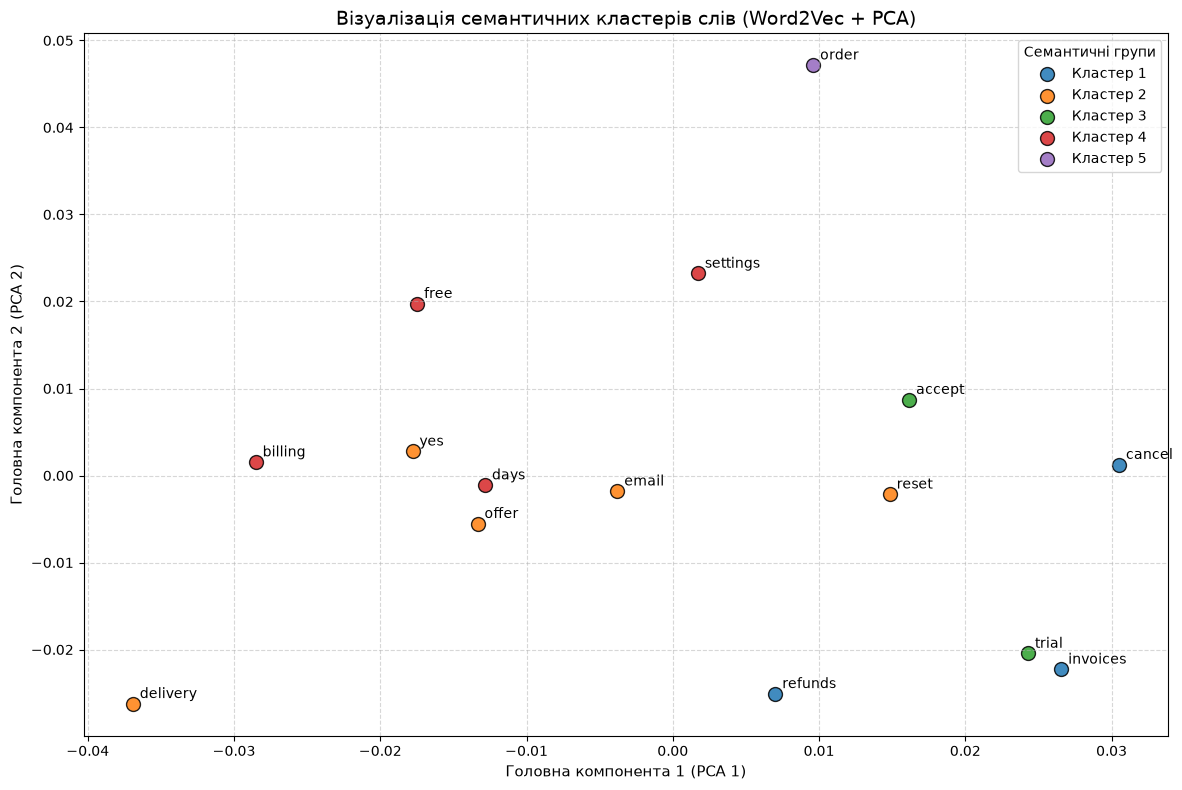

In [9]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2, random_state=42)
vectors_2d = pca.fit_transform(word_vectors)

plt.figure(figsize=(12, 8))
colors = plt.cm.tab10.colors

for cluster_id in range(num_clusters):
    idx = (cluster_labels == cluster_id)
    
    plt.scatter(
        vectors_2d[idx, 0],
        vectors_2d[idx, 1],
        color=colors[cluster_id % len(colors)],
        label=f"Кластер {cluster_id + 1}",
        s=100,
        alpha=0.85,
        edgecolors="black"
    )

for i, word in enumerate(words):
    plt.annotate(
        word,
        xy=(vectors_2d[i, 0], vectors_2d[i, 1]),
        xytext=(5, 4),
        textcoords="offset points",
        fontsize=10
    )

plt.title("Візуалізація семантичних кластерів слів (Word2Vec + PCA)", fontsize=14)
plt.xlabel("Головна компонента 1 (PCA 1)", fontsize=11)
plt.ylabel("Головна компонента 2 (PCA 2)", fontsize=11)
plt.legend(title="Семантичні групи", loc="best")
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("semantic_clusters.png", dpi=300)
plt.show()